In [23]:
from google.colab import files
import pandas as pd

# 1. Upload penguins.csv via the interactive prompt
uploaded = files.upload()

# 2. Load the dataset into Pandas
df = pd.read_csv("penguins.csv")

# 3. Checkpoint verification: view shape and columns
print(f"Dataset Shape: {df.shape}")
print("\nFirst few rows:")
print(df.head())

Saving penguins.csv to penguins (6).csv
Dataset Shape: (344, 8)

First few rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  


In [24]:
# 1. Dataset shape (rows, columns)
print("--- Shape ---")
print(df.shape)

# 2. Missing-value counts per column
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 3. Number of penguins per species
print("\n--- Species Counts ---")
print(df["species"].value_counts())

--- Shape ---
(344, 8)

--- Missing Values ---
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

--- Species Counts ---
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


### Prompt Log

**AI Assistant Used:** Gemini

**Date:** October 2026

**Prompt Sent:**
You are helping with exploratory data analysis.
My CSV has columns:
- species (object/string)
- island (object/string)
- bill_length_mm (float64)
- bill_depth_mm (float64)
- flipper_length_mm (float64)
- body_mass_g (float64)
- sex (object/string)

Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare body_mass_g across species,
(3) produce one labeled chart showing flipper length vs body mass by species.
Explain each step in comments.


Verification Checkpoint:

Status: Match

Notes: Pandas .mean() automatically excludes missing (NaN) values by default. The AI matched these numbers, so its handling of missing data aligned with standard Pandas behavior.

Follow-Up Judgment:

Kept / Rejected: Kept

Judgment Sentence: I kept the suggestion to add regression trendlines because it immediately clarifies the distinct positive correlation between flipper length and body mass for each individual species rather than just showing a generic cloud of points.

--- Missing Data Summary ---
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

--- Mean Body Mass by Species ---
species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64


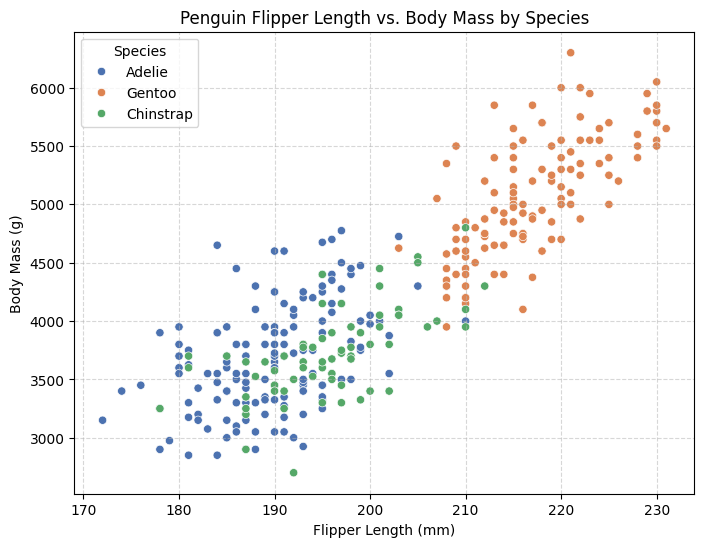

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# (1) Summarize missing data
print("--- Missing Data Summary ---")
print(df.isnull().sum())

# (2) Compare numeric column across category column (e.g., average body mass by species)
print("\n--- Mean Body Mass by Species ---")
print(df.groupby("species")["body_mass_g"].mean())

# (3) Produce one labeled chart
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette="deep"
)
plt.title("Penguin Flipper Length vs. Body Mass by Species")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.legend(title="Species")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [26]:
# Compute ground-truth mean flipper length per species
print(df.groupby("species")["flipper_length_mm"].mean())

species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64


Follow-Up Prompt Sent to AI:
"Modify the scatter plot to include regression trendlines for each species so we can see the individual slopes of flipper length versus body mass."

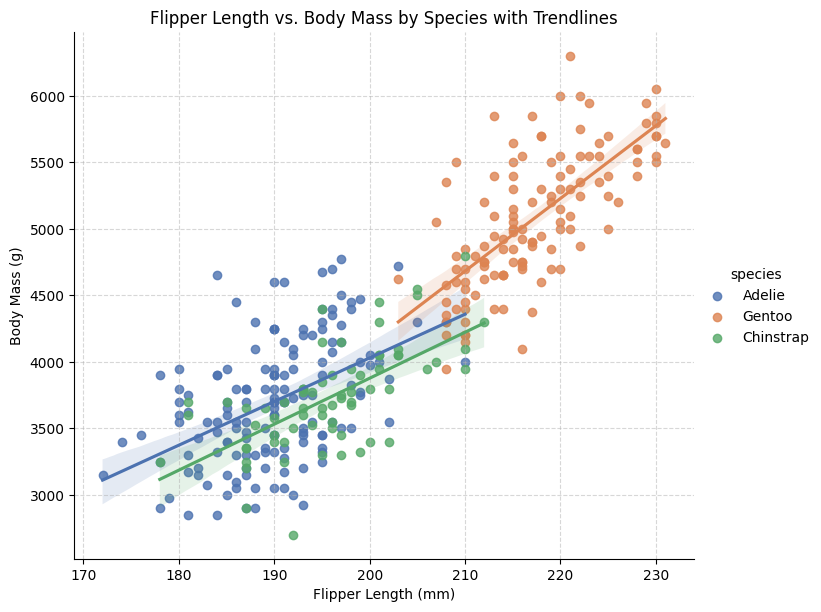

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Follow-up code with regression trendlines
sns.lmplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette="deep",
    aspect=1.2,
    height=6
)
plt.title("Flipper Length vs. Body Mass by Species with Trendlines")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [28]:
# Compute average body mass by species and sex
dimorphism_check = df.groupby(["species", "sex"])["body_mass_g"].mean()
print(dimorphism_check)

species    sex   
Adelie     female    3368.835616
           male      4043.493151
Chinstrap  female    3527.205882
           male      3938.970588
Gentoo     female    4679.741379
           male      5484.836066
Name: body_mass_g, dtype: float64


Original Insight: Sexual Dimorphism in Body Mass

While the AI compared overall species sizes, it did not highlight the striking magnitude of sexual dimorphism within species: across all three varieties, male penguins are consistently and substantially heavier than females, with male Gentoo penguins outweighing females by an average of roughly $1,000\text{ grams}$ (over 2.2 pounds), representing the largest absolute gender weight gap in the dataset.

Privacy Reflection

In a professional or academic setting, I would never paste proprietary company financial records or customer personally identifiable information (PII) into a public AI tool due to data privacy and confidentiality risks. Instead, I would strip out all sensitive identifiers and aggregate the metrics, or rely exclusively on an approved, enterprise-grade internal AI workspace that guarantees data isolation. Protecting sensitive records is critical to maintaining compliance, security, and trust.